## UTS GRAF SAINS DATA
**M. Raihan Firdaus**
**23031554164**

***Persiapan Data dan Neo4j***

In [143]:
import sys
import os
import argparse
from tqdm import tqdm
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt


print(sys.executable)
print(sys.version)

c:\Users\Hanseok\Documents\Semester 7\Graf Sains Data\UTS\myenv\Scripts\python.exe
3.12.0 (tags/v3.12.0:0fb18b0, Oct  2 2023, 13:03:39) [MSC v.1935 64 bit (AMD64)]


In [144]:
# neo4j>=4.0,<4.3
# imdbpy==2020.9.25
# nose==1.3.7
# cinemagoerng>=0.4
# imdbinfo>=0.5
# imdbpy>=2020.9.25
# neo4j==4.2.1

# Dependency yang digunakan

In [145]:
import pandas as pd
import neo4j

print("Pandas:", pd.__version__)
print("Neo4j:", neo4j.__version__)

Pandas: 3.0.6
Neo4j: 5.26.0


## Driver Neo4J

In [146]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "12345678")

In [147]:
def add_friend(driver, name, friend_name):
    with driver.session(database="neo4j") as session:
        session.run(
            """
            MERGE (a:Person {name: $name})
            MERGE (friend:Person {name: $friend_name})
            MERGE (a)-[:KNOWS]->(friend)
            """,
            name=name,
            friend_name=friend_name
        )

In [148]:

def print_friends(driver, name):
    with driver.session(database="neo4j") as session:
        result = session.run(
            """
            MATCH (a:Person)-[:KNOWS]->(friend)
            WHERE a.name = $name
            RETURN friend.name AS friend_name
            ORDER BY friend.name
            """,
            name=name
        )

        for record in result:
            print(record["friend_name"])

In [149]:
with GraphDatabase.driver(URI, auth=AUTH, ) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


**Jawaban Pertanyaan Penduluan**

1. Disini saya menggunakan Database neo4j dengan nama database di lokal saya "UTS-GSD"
2. akses lain yang bisa digunakan adalah CREATE untuk membuat node atau relasi, MATCH untuk mencari data, DELETE untuk menghapus node atau relasi, dan MERGE untuk membuat data jika belum tersedia.
3. directed graph, karena tiap node dalam graf memiliki arah tujuan ke node lainnya.

## Import Data

In [150]:
# Timestamp : Waktu format unix epoch
# visitorid : uniqueid pengunjung
# event : jenis interaksi default: view, addtocart, transaction
# itemid: ID unik produk
# transactionid : ID transaksi, hanya saat event berjenis 'transaction'

In [151]:
user = "neo4j"
password = "12345678"

In [152]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver(URI, auth=(user, password))
session = driver.session(database="system")

In [153]:
def create_constraints(session):
    # Membuat constraint biar node ga duplikat
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        
        UNION ALL
        
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        
        UNION ALL
        
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)    

In [154]:
def parse_arguments():
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events.csv) ke database Neo4J."
    )
    parser.add_argument(
        "-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)"
    )
    parser.add_argument(
        "-p",
        "--password",
        default="12345678",
        help="Password Neo4J (default: neo4j)",
    )
    parser.add_argument(
        "-b",
        "--bolt",
        default="neo4j://127.0.0.1:7687",
        help="Neo4J URI / Bolt (default: neo4j://127.0.0.1:7687)",
    )
    parser.add_argument(
        "-s",
        "--source",
        default="data",
        help="Direktori/folder sumber data (default: data)",
    )
    return parser.parse_args([])

In [155]:
args = parse_arguments()
csv_file_path = os.path.join(args.source, "events.csv")
if not os.path.exists(csv_file_path):
    print(f"Error: File {csv_file_path} tidak ditemukan!")
    sys.exit(1)
else:
    print(f"File {csv_file_path} berhasil ditemukan dan siap diproses!")


File data\events.csv berhasil ditemukan dan siap diproses!


In [156]:
df_events = pd.read_csv(csv_file_path, nrows = 5)
print(df_events)

       timestamp  visitorid event  itemid  transactionid
0  1433221332117     257597  view  355908            NaN
1  1433224214164     992329  view  248676            NaN
2  1433221999827     111016  view  318965            NaN
3  1433221955914     483717  view  253185            NaN
4  1433221337106     951259  view  367447            NaN


In [157]:
try:
    driver = GraphDatabase.driver(
        args.bolt, auth=(args.user, args.password)
    )
    driver.verify_connectivity()
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

In [158]:
batch_size = 10000

# Menghitung total baris
total_rows = sum(1 for _ in open(csv_file_path)) - 1
total_chunks = (total_rows // batch_size) + 1

with driver.session() as session:
    create_constraints(session)
    
    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)
    
    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        # Membersihkan data null/NaN pada transactionid
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )
        
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor berhasil.")

Membaca file data dari: data\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 276/276 [06:53<00:00,  1.50s/it]

Proses impor berhasil.


In [159]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        
        UNION ALL
        
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        
        UNION ALL
        
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)
    print(f"Berhasil mengimpor {len(batch)} baris data pada batch ini.")

**Soal 1**

Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yg dipilih per individu tidak
boleh sama dalam 1 kelas.
Misal: Fold training (P1) → 01/2023 - 03/2023; Fold testing (P2) 01/2024 - 06/2024.

In [160]:
import pandas as pd

# dataset asli
df = pd.read_csv(r"data\events.csv")

# Mengubah timestamp unix menjadi datetime
df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')

print("Waktu terawal:", df['datetime'].min())
print("Waktu terakhir:", df['datetime'].max())

Waktu terawal: 2015-05-03 03:00:04.384000
Waktu terakhir: 2015-09-18 02:59:47.788000


In [161]:
# Fold P1 (untuk train)
start_p1 = "2015-06-17"
end_p1 = "2015-06-26"

# Fold P2 (untuk test)
start_p2 = "2015-06-27"
end_p2 = "2015-06-30"

disini sesuai instruksi nomer 1, saya membuat kombinasis fold P1 yaitu tanggal 17 Juni - 26 Juni, dan fold P2 tanggal 27 juni - 30 juni.

**Nomer 2**

Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [162]:
mask_p1 = (df['datetime'] >= start_p1) & (df['datetime'] <= end_p1)
mask_p2 = (df['datetime'] >= start_p2) & (df['datetime'] <= end_p2)

df_p1 = df.loc[mask_p1]
df_p2 = df.loc[mask_p2]

In [163]:
output_p1 = r"data\events_p1_train.csv"
output_p2 = r"data\events_p2_test.csv"
df_p1.drop(columns=['datetime']).to_csv(output_p1, index=False)
df_p2.drop(columns=['datetime']).to_csv(output_p2, index=False)

print("Proses Filter Selesai!")
print(f"Data Fold Training (P1) -> {output_p1} ({len(df_p1):,} baris)")
print(f"Data Fold Testing  (P2) -> {output_p2} ({len(df_p2):,} baris)")

Proses Filter Selesai!
Data Fold Training (P1) -> data\events_p1_train.csv (188,184 baris)
Data Fold Testing  (P2) -> data\events_p2_test.csv (55,656 baris)


In [164]:
df_filtered = pd.concat([df_p1, df_p2])
df_filtered = df_filtered.drop(columns=['datetime'])

output_path = r"data\events_filtered.csv"
df_filtered.to_csv(output_path, index=False)

print("Data hasil filter")
print(f"Data Fold Train (P1): {len(df_p1)} baris")
print(f"Data Fold Test (P2): {len(df_p2)} baris")
print(f"Total Data Interaksi: {len(df_filtered)} baris")
print(f"File filter gabungan: {output_path}")

Data hasil filter
Data Fold Train (P1): 188184 baris
Data Fold Test (P2): 55656 baris
Total Data Interaksi: 243840 baris
File filter gabungan: data\events_filtered.csv


## Nomer 3

3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah
masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [165]:
args = parse_arguments()
csv_file_path_P1 = os.path.join(args.source, "events_p1_train.csv")
if not os.path.exists(csv_file_path_P1):
    print(f"Error: File {csv_file_path_P1} tidak ditemukan!")
    sys.exit(1)
else:
    print(f"File {csv_file_path_P1} ditemukan")


File data\events_p1_train.csv ditemukan


In [166]:
batch_size = 10000

# Menghitung total baris
total_rows = sum(1 for _ in open(csv_file_path_P1)) - 1
total_chunks = (total_rows // batch_size) + 1

with driver.session(database="neo4j") as session:
    create_constraints(session)
    
    print(f"Membaca file data dari: {csv_file_path_P1}")
    chunks = pd.read_csv(csv_file_path_P1, chunksize=batch_size)
    
    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        # karena transactionid banyak berisi NaN, maka dihapus
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )
        
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor berhasil.")

C:\Users\Hanseok\AppData\Local\Temp\ipykernel_2188\1171153582.py:7: DeprecationWarning: Using a driver after it has been closed is deprecated. Future versions of the driver will raise an error.
  with driver.session(database="neo4j") as session:


Membaca file data dari: data\events_p1_train.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data:   0%|          | 0/19 [00:00<?, ?it/s]Received notification from DBMS server: {severity: WARNING} {code: Neo.ClientNotification.Statement.FeatureDeprecationWarning} {category: DEPRECATION} {title: This feature is deprecated and will be removed in future versions.} {description: CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }} {position: line: 7, column: 5, offset: 139} for query: "\n    UNWIND $batch AS row\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'addtocart'\n        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'trans

Berhasil mengimpor 10000 baris data pada batch ini.


Mengimpor Batch Data:   5%|▌         | 1/19 [00:02<00:36,  2.02s/it]Received notification from DBMS server: {severity: WARNING} {code: Neo.ClientNotification.Statement.FeatureDeprecationWarning} {category: DEPRECATION} {title: This feature is deprecated and will be removed in future versions.} {description: CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }} {position: line: 7, column: 5, offset: 139} for query: "\n    UNWIND $batch AS row\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'addtocart'\n        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n        WITH v, i, row\n        WITH v, i, row WHERE row.event 

...

Berhasil mengimpor 10000 baris data pada batch ini.


Mengimpor Batch Data:  95%|█████████▍| 18/19 [00:22<00:01,  1.59s/it]Received notification from DBMS server: {severity: WARNING} {code: Neo.ClientNotification.Statement.FeatureDeprecationWarning} {category: DEPRECATION} {title: This feature is deprecated and will be removed in future versions.} {description: CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }} {position: line: 7, column: 5, offset: 139} for query: "\n    UNWIND $batch AS row\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'addtocart'\n        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n        WITH v, i, row\n        WITH v, i, row WHERE row.event

Berhasil mengimpor 8184 baris data pada batch ini.


Mengimpor Batch Data: 100%|██████████| 19/19 [00:30<00:00,  1.59s/it]

Proses impor berhasil.


In [167]:
query = """
MATCH (n)
WHERE n:Visitor OR n:Item
UNWIND labels(n) AS jenis_simpul
RETURN jenis_simpul, count(n) AS jumlah_simpul
ORDER BY jumlah_simpul DESC
"""

In [168]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        result = session.run(query)
        df_komposisi = pd.DataFrame([r.data() for r in result])
df_komposisi

,jenis_simpul,jumlah_simpul
0,Visitor,1407580
1,Item,235061


**Soal 4**

Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [169]:
df_p1 = pd.read_csv(r"data\events_p1_train.csv")

user_cat = df_p1['visitorid'].astype('category')
item_cat = df_p1['itemid'].astype('category')

user_indices = user_cat.cat.codes
item_indices = item_cat.cat.codes

n_users = len(user_cat.cat.categories)
n_items = len(item_cat.cat.categories)

In [170]:
# VSM 
# bobot interaksi
bobot_map = {'view': 1, 'addtocart': 2, 'transaction': 3}
weights = df_p1['event'].map(bobot_map)

# Sparse csr untuk membuat matrix
vsm_matrix = sp.csr_matrix(
    (weights, (user_indices, item_indices)), 
    shape=(n_users, n_items)
)

In [171]:
# vektor 
sample_users = user_cat.cat.categories[:10]
sample_items = item_cat.cat.categories[:16]
sample_df = pd.DataFrame(
    vsm_matrix[:10, :16].toarray(),
    index=[f"User_{uid}" for uid in sample_users],
    columns=[f"Item_{iid}" for iid in sample_items]
)
print("Cuplikan Representasi Vektor (10 User pertama x 16 Item pertama):")
display(sample_df)

Cuplikan Representasi Vektor (10 User pertama x 16 Item pertama):


,Item_15,Item_16,Item_26,Item_32,Item_42,Item_46,Item_55,Item_60,Item_66,Item_73,Item_78,Item_80,Item_90,Item_102,Item_105,Item_106
User_13,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
User_60,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
User_64,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
User_65,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
User_91,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
User_132,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
User_149,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
User_151,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
User_158,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
User_163,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


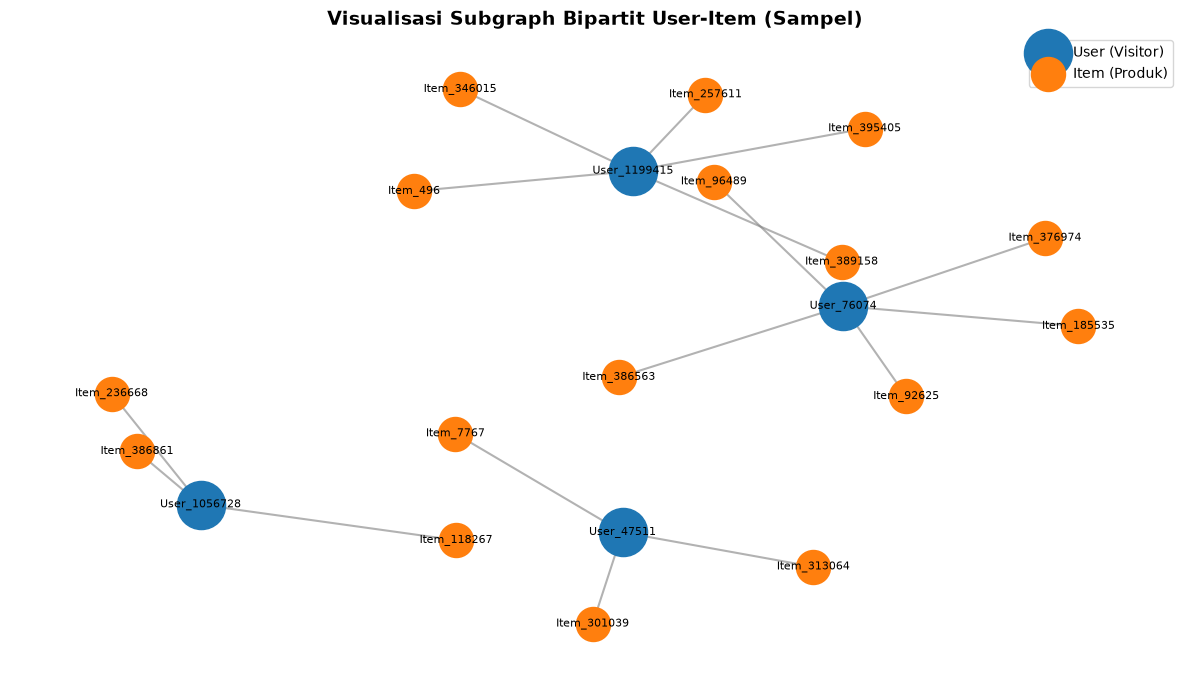

In [172]:
user_counts = df_p1['visitorid'].value_counts()
sample_user_ids = user_counts[(user_counts >= 3) & (user_counts <= 6)].head(4).index
sub_df = df_p1[df_p1['visitorid'].isin(sample_user_ids)]

B = nx.Graph()
for _, row in sub_df.iterrows():
    u_node = f"User_{row['visitorid']}"
    i_node = f"Item_{row['itemid']}"
    B.add_node(u_node, node_type="User")
    B.add_node(i_node, node_type="Item")
    B.add_edge(u_node, i_node, event=row['event'])

plt.figure(figsize=(12, 7))
pos = nx.spring_layout(B, seed=42, k=0.7)
user_nodes = [n for n, d in B.nodes(data=True) if d['node_type'] == 'User']
item_nodes = [n for n, d in B.nodes(data=True) if d['node_type'] == 'Item']
nx.draw_networkx_nodes(B, pos, nodelist=user_nodes, node_color='#1f77b4', node_size=1200, label='User (Visitor)')
nx.draw_networkx_nodes(B, pos, nodelist=item_nodes, node_color='#ff7f0e', node_size=600, label='Item (Produk)')
nx.draw_networkx_edges(B, pos, edge_color='gray', alpha=0.6, width=1.5)
nx.draw_networkx_labels(B, pos, font_size=8, font_family='sans-serif', font_color='black')
plt.title("Visualisasi Subgraph Bipartit User-Item (Sampel)", fontsize=14, fontweight='bold')
plt.legend(scatterpoints=1, loc='upper right')
plt.axis('off')
plt.tight_layout()
plt.show()

**SOAL 5**

Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (di-
mensi, shape, plot networkx, dst.)!

In [173]:
# 1. Menggunakan data P1 Training
df_p1 = pd.read_csv(r"data\events_p1_train.csv")

item_cat = df_p1['itemid'].astype('category')
user_cat = df_p1['visitorid'].astype('category')


In [174]:
item_indices = item_cat.cat.codes
user_indices = user_cat.cat.codes
n_items = len(item_cat.cat.categories)
n_users = len(user_cat.cat.categories)


In [175]:
# 3. Bobot interaksi
bobot_map = {'view': 1, 'addtocart': 2, 'transaction': 3}
weights = df_p1['event'].map(bobot_map)

vsm_item_matrix = sp.csr_matrix(
    (weights, (item_indices, user_indices)),
    shape=(n_items, n_users)
)

In [176]:
total_elemen = n_items * n_users
non_zero = vsm_item_matrix.nnz
sparsity = (1.0 - (non_zero / total_elemen)) * 100
print(f"1. Dimensi Ruang Vektor (Jumlah Fitur/User) : {n_users:,} dimensi")
print(f"2. Shape Matriks VSM (Item x User)          : {vsm_item_matrix.shape}")
print(f"3. Total Pasangan Berinteraksi (Non-Zero)  : {non_zero:,}")
print(f"4. Tingkat Kerapatan (Density)              : {(non_zero / total_elemen) * 100:.5f}%")
print(f"5. Tingkat Keringkihan (Sparsity)           : {sparsity:.5f}%\n")


1. Dimensi Ruang Vektor (Jumlah Fitur/User) : 98,564 dimensi
2. Shape Matriks VSM (Item x User)          : (59738, 98564)
3. Total Pasangan Berinteraksi (Non-Zero)  : 145,853
4. Tingkat Kerapatan (Density)              : 0.00248%
5. Tingkat Keringkihan (Sparsity)           : 99.99752%



In [177]:
sample_items = item_cat.cat.categories[:5]
sample_users = user_cat.cat.categories[:8]
sample_item_df = pd.DataFrame(
    vsm_item_matrix[:5, :8].toarray(),
    index=[f"Item_{iid}" for iid in sample_items],
    columns=[f"User_{uid}" for uid in sample_users]
)
print("Cuplikan Representasi Vektor (5 Item pertama x 8 User pertama):")
display(sample_item_df)


Cuplikan Representasi Vektor (5 Item pertama x 8 User pertama):


,User_13,User_60,User_64,User_65,User_91,User_132,User_149,User_151
Item_15,0,0,0,0,0,0,0,0
Item_16,0,0,0,0,0,0,0,0
Item_26,0,0,0,0,0,0,0,0
Item_32,0,0,0,0,0,0,0,0
Item_42,0,0,0,0,0,0,0,0


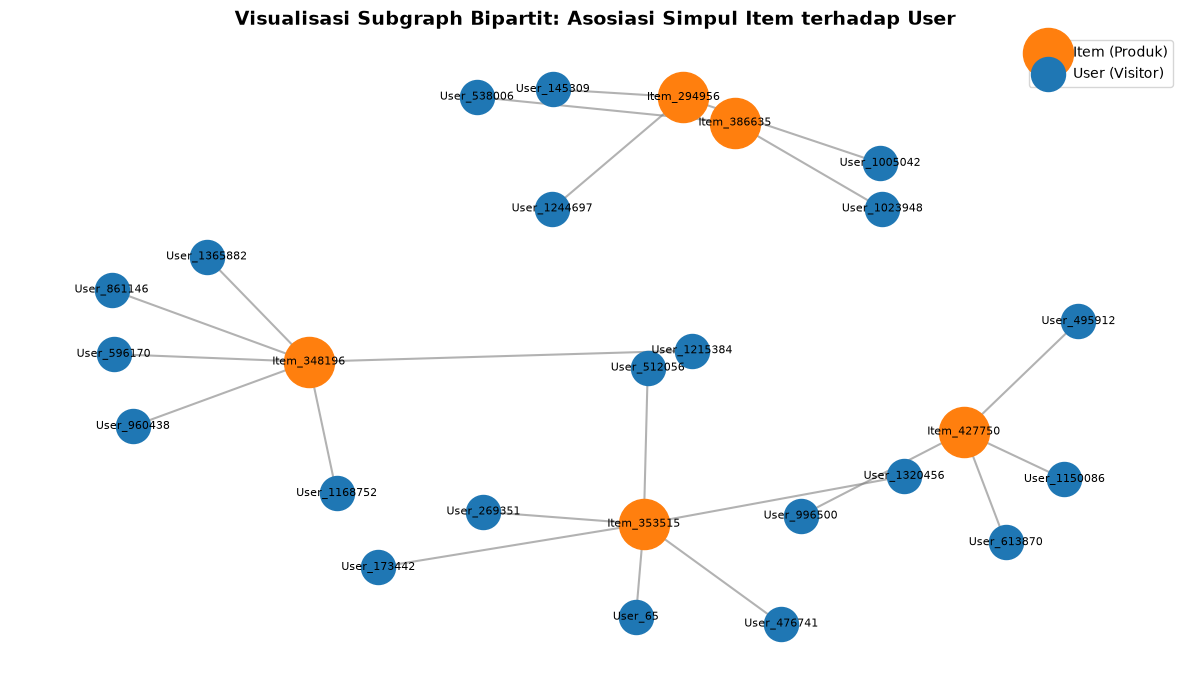

In [178]:
# Mengambil sampel 4 item
item_counts = df_p1['itemid'].value_counts()
sample_item_ids = item_counts[(item_counts >= 3) & (item_counts <= 6)].head(5).index
sub_df_item = df_p1[df_p1['itemid'].isin(sample_item_ids)]

# membuat Graf Bipartit untuk Item
B_item = nx.Graph()

for _, row in sub_df_item.iterrows():
    u_node = f"User_{row['visitorid']}"
    i_node = f"Item_{row['itemid']}"
    B_item.add_node(i_node, node_type="Item")
    B_item.add_node(u_node, node_type="User")
    B_item.add_edge(i_node, u_node, event=row['event'])

plt.figure(figsize=(12, 7))
pos = nx.spring_layout(B_item, seed=42, k=0.7)
item_nodes = [n for n, d in B_item.nodes(data=True) if d['node_type'] == 'Item']
user_nodes = [n for n, d in B_item.nodes(data=True) if d['node_type'] == 'User']
nx.draw_networkx_nodes(B_item, pos, nodelist=item_nodes, node_color='#ff7f0e', node_size=1300, label='Item (Produk)')
nx.draw_networkx_nodes(B_item, pos, nodelist=user_nodes, node_color='#1f77b4', node_size=600, label='User (Visitor)')
nx.draw_networkx_edges(B_item, pos, edge_color='gray', alpha=0.6, width=1.5)
nx.draw_networkx_labels(B_item, pos, font_size=8, font_family='sans-serif', font_color='black')

plt.title("Visualisasi Subgraph Bipartit: Asosiasi Simpul Item terhadap User", fontsize=14, fontweight='bold')
plt.legend(scatterpoints=1, loc='upper right')
plt.axis('off')
plt.tight_layout()
plt.show()


**Nomer 6**

Dari hasil eksplorasi nomer 4 dan 5, proyeksi yang memiliki hasil lebih baik yaitu:

1. Dalam hal efisiensi, yang lebih efisien adalah simpul item, karena hanya memiliki 59,738 jumlah fitur, lebih kecil daripada User, sehingga komputasinya jauh lebih hemat memori.
2. Lebih stabil, Relasi antar item bersifat lebih stabil dibandingkan preferensi pengguna yang lebih dinamis. (memungkinkan komputasi offline dan caching)

3. Lebih efektif, Mengurangi dampak sparsity, karena riwayat interaksi produk lebih kaya dibandingkan riwayat individu pengunjung yang rata-rata hanya melihat sedikit barang. Pendekatan ini sejalan dengan standar industri e-commerce (Item-based Collaborative Filtering).

**Nomer 7**

Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggu-
nakan Python

(a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri
record acuannya)!

(b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-
nya!

In [179]:
query_7a = """
MATCH (target:Item {itemId: 309778})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(other:Item)
WHERE target <> other
WITH target, other, count(DISTINCT v) AS intersection
MATCH (target)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v1:Visitor)
WITH target, other, intersection, count(DISTINCT v1) AS count_target
MATCH (other)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v2:Visitor)
WITH target, other, intersection, count_target, count(DISTINCT v2) AS count_other
WITH target, other, round((1.0 * intersection) / (count_target + count_other - intersection), 4) AS jaccard_similarity
RETURN target.itemId AS item_acuan, 
       other.itemId AS item_serupa, 
       jaccard_similarity AS similarity_score
ORDER BY similarity_score DESC
LIMIT 5
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        result = session.run(query_7a)
        df_top5 = pd.DataFrame([r.data() for r in result])

print("5 Records dengan Similarity Tertinggi untuk Item 309778")
display(df_top5)


5 Records dengan Similarity Tertinggi untuk Item 309778


,item_acuan,item_serupa,similarity_score
0,309778,257040,0.1068
1,309778,360487,0.0639
2,309778,87557,0.0459
3,309778,347414,0.0449
4,309778,135900,0.0440


In [180]:
# 1. Query write
query_7b = """
MATCH (target:Item {itemId: 309778})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(other:Item)
WHERE target <> other
WITH target, other, count(DISTINCT v) AS intersection
MATCH (target)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v1:Visitor)
WITH target, other, intersection, count(DISTINCT v1) AS count_target
MATCH (other)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v2:Visitor)
WITH target, other, intersection, count_target, count(DISTINCT v2) AS count_other
WITH target, other, round((1.0 * intersection) / (count_target + count_other - intersection), 4) AS jaccard_similarity
ORDER BY jaccard_similarity DESC
LIMIT 5
MERGE (target)-[s:SIMILAR_TO]->(other)
SET s.score = jaccard_similarity
"""

# 2. Query untuk membuktikan relasi baru telah tersimpan di graf
query_verify = """
MATCH (target:Item {itemId: 309778})-[s:SIMILAR_TO]->(other:Item)
RETURN target.itemId AS item_acuan, 
       type(s) AS jenis_relasi, 
       other.itemId AS item_terhubung, 
       s.score AS similarity_score
ORDER BY similarity_score DESC
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        session.run(query_7b)
        print("Nilai similarity berhasil ditulis kembali ke graf (Relasi :SIMILAR_TO terbentuk)!\n")
        
        res_verify = session.run(query_verify)
        df_verified = pd.DataFrame([r.data() for r in res_verify])

print("Hasil Query Relasi Similarity yang Tersimpan di Graf")
display(df_verified)


Nilai similarity berhasil ditulis kembali ke graf (Relasi :SIMILAR_TO terbentuk)!

Hasil Query Relasi Similarity yang Tersimpan di Graf


,item_acuan,jenis_relasi,item_terhubung,similarity_score
0,309778,SIMILAR_TO,257040,0.1068
1,309778,SIMILAR_TO,360487,0.0639
2,309778,SIMILAR_TO,87557,0.0459
3,309778,SIMILAR_TO,5470,0.0457
4,309778,SIMILAR_TO,347414,0.0449
5,309778,SIMILAR_TO,135900,0.0440
6,309778,SIMILAR_TO,178362,0.0321


**Soal 8**

8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah
perhitungan similarity!

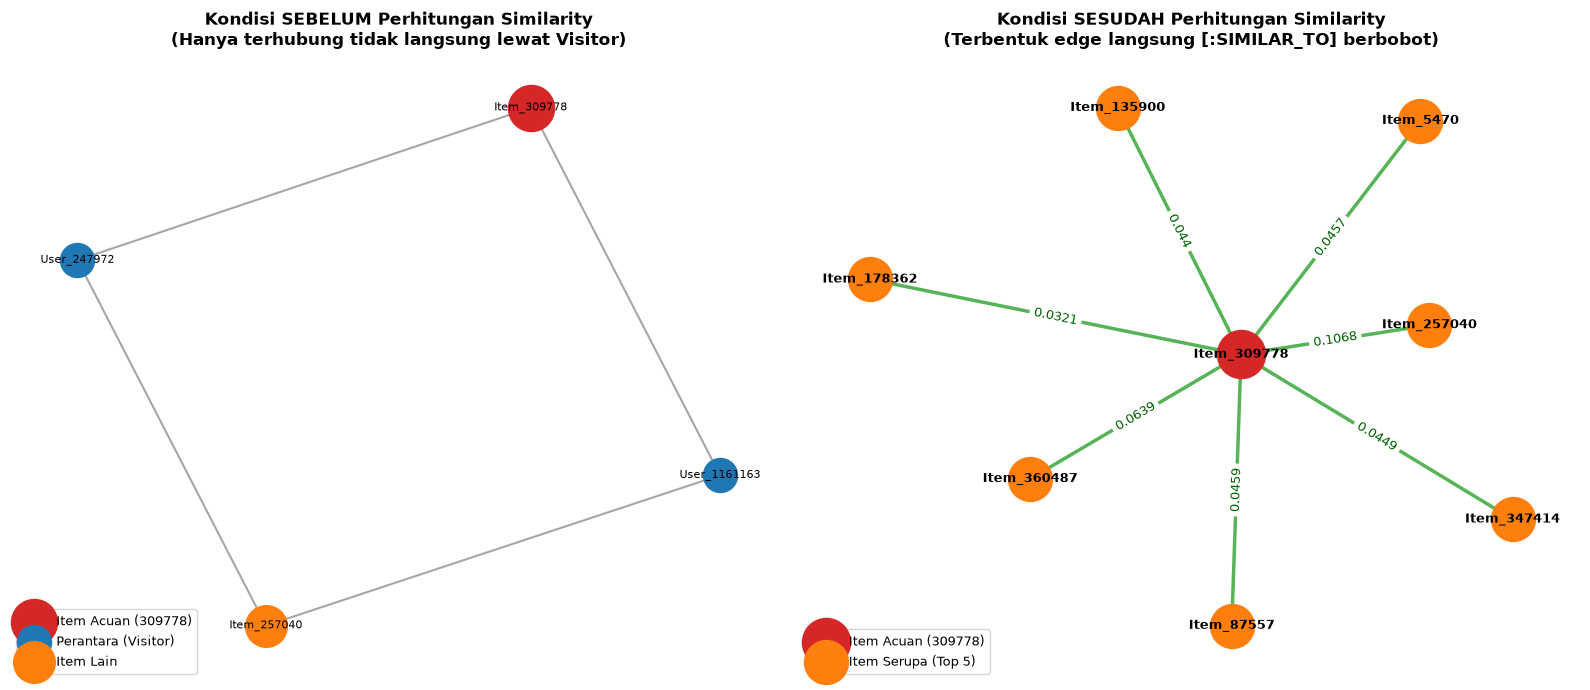

In [181]:
# Inisialisasi dua graf
G_sebelum = nx.Graph()
G_sesudah = nx.Graph()

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        # 1. Ambil data ksebelum
        query_bef = """
        MATCH (target:Item {itemId: 309778})<-[:VIEWED]-(v:Visitor)-[:VIEWED]->(other:Item)
        WHERE other.itemId IN [257040, 360487, 5470, 347414, 178362]
        RETURN target.itemId AS target, v.visitorId AS visitor, other.itemId AS other
        LIMIT 10
        """
        for r in session.run(query_bef):
            t_node = f"Item_{r['target']}"
            v_node = f"User_{r['visitor']}"
            o_node = f"Item_{r['other']}"
            G_sebelum.add_node(t_node, type="target")
            G_sebelum.add_node(v_node, type="visitor")
            G_sebelum.add_node(o_node, type="item")
            G_sebelum.add_edge(t_node, v_node)
            G_sebelum.add_edge(v_node, o_node)

        # 2. Ambil data sesudah
        query_aft = """
        MATCH (target:Item {itemId: 309778})-[s:SIMILAR_TO]->(other:Item)
        RETURN target.itemId AS target, other.itemId AS other, s.score AS score
        """
        for r in session.run(query_aft):
            t_node = f"Item_{r['target']}"
            o_node = f"Item_{r['other']}"
            G_sesudah.add_node(t_node, type="target")
            G_sesudah.add_node(o_node, type="item")
            G_sesudah.add_edge(t_node, o_node, weight=r['score'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

pos1 = nx.spring_layout(G_sebelum, seed=42)
t_nodes_1 = [n for n, d in G_sebelum.nodes(data=True) if d.get('type') == 'target']
v_nodes_1 = [n for n, d in G_sebelum.nodes(data=True) if d.get('type') == 'visitor']
o_nodes_1 = [n for n, d in G_sebelum.nodes(data=True) if d.get('type') == 'item']
nx.draw_networkx_nodes(G_sebelum, pos1, nodelist=t_nodes_1, node_color='#d62728', node_size=1100, label='Item Acuan (309778)', ax=ax1)
nx.draw_networkx_nodes(G_sebelum, pos1, nodelist=v_nodes_1, node_color='#1f77b4', node_size=600, label='Perantara (Visitor)', ax=ax1)
nx.draw_networkx_nodes(G_sebelum, pos1, nodelist=o_nodes_1, node_color='#ff7f0e', node_size=900, label='Item Lain', ax=ax1)
nx.draw_networkx_edges(G_sebelum, pos1, edge_color='gray', width=1.5, alpha=0.7, ax=ax1)
nx.draw_networkx_labels(G_sebelum, pos1, font_size=8, font_color='black', ax=ax1)
ax1.set_title("Kondisi SEBELUM Perhitungan Similarity\n(Hanya terhubung tidak langsung lewat Visitor)", fontsize=12, fontweight='bold')
ax1.legend(loc='lower left', fontsize=9)
ax1.axis('off')


pos2 = nx.spring_layout(G_sesudah, seed=42)
t_nodes_2 = [n for n, d in G_sesudah.nodes(data=True) if d.get('type') == 'target']
o_nodes_2 = [n for n, d in G_sesudah.nodes(data=True) if d.get('type') == 'item']
nx.draw_networkx_nodes(G_sesudah, pos2, nodelist=t_nodes_2, node_color='#d62728', node_size=1200, label='Item Acuan (309778)', ax=ax2)
nx.draw_networkx_nodes(G_sesudah, pos2, nodelist=o_nodes_2, node_color='#ff7f0e', node_size=1000, label='Item Serupa (Top 5)', ax=ax2)
nx.draw_networkx_edges(G_sesudah, pos2, edge_color='#2ca02c', width=2.5, alpha=0.8, ax=ax2)
nx.draw_networkx_labels(G_sesudah, pos2, font_size=9, font_color='black', font_weight='bold', ax=ax2)

# Label bobot similarity
edge_labels = {(u, v): f"{d['weight']}" for u, v, d in G_sesudah.edges(data=True)}
nx.draw_networkx_edge_labels(G_sesudah, pos2, edge_labels=edge_labels, font_size=9, font_color='darkgreen', ax=ax2)

ax2.set_title("Kondisi SESUDAH Perhitungan Similarity\n(Terbentuk edge langsung [:SIMILAR_TO] berbobot)", fontsize=12, fontweight='bold')
ax2.legend(loc='lower left', fontsize=9)
ax2.axis('off')

plt.tight_layout()
plt.show()


**Soal 2.2 Nomer 1**

1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu
(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!
(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

In [182]:
# 1. Membaca data training P1
df_p1 = pd.read_csv(r"data\events_p1_train.csv")

# 2. Rekonstruksi Matriks VSM User
user_cat = df_p1['visitorid'].astype('category')
item_cat = df_p1['itemid'].astype('category')

user_indices = user_cat.cat.codes
item_indices = item_cat.cat.codes

n_users = len(user_cat.cat.categories)
n_items = len(item_cat.cat.categories)

bobot_map = {'view': 1, 'addtocart': 2, 'transaction': 3}
weights = df_p1['event'].map(bobot_map)

vsm_matrix = sp.csr_matrix((weights, (user_indices, item_indices)), shape=(n_users, n_items))

#target user
target_user = 1127595
target_idx = user_cat.cat.categories.get_loc(target_user)

print(f"Target User yang Dipilih: {target_user}")

# cari tetangga dan cosine

target_vec = vsm_matrix[target_idx]
sims = cosine_similarity(target_vec, vsm_matrix).flatten()
sims[target_idx] = -1.0  # Abaikan diri sendiri

K = 5
top_k_idx = np.argsort(sims)[::-1][:K]
top_k_users = user_cat.cat.categories[top_k_idx]
top_k_sims = sims[top_k_idx]

df_knn = pd.DataFrame({
    'Peringkat': range(1, K + 1),
    'Visitor_ID': top_k_users,
    'Cosine_Similarity': top_k_sims
})
display(df_knn)

# Skor rekomendasi
seen_items = set(df_p1[df_p1['visitorid'] == target_user]['itemid'])

candidate_scores = {}
for n_idx, sim in zip(top_k_idx, top_k_sims):
    row = vsm_matrix[n_idx].tocoo()
    for c_idx, val in zip(row.col, row.data):
        item_id = item_cat.cat.categories[c_idx]
        if item_id not in seen_items:
            candidate_scores[item_id] = candidate_scores.get(item_id, 0.0) + (sim * val)

sorted_rec = sorted(candidate_scores.items(), key=lambda x: x[1], reverse=True)
df_rec = pd.DataFrame(sorted_rec[:5], columns=['Item_ID', 'Skor_Rekomendasi'])

print("\nHasil Rekomendasi Item:")
display(df_rec)


Target User yang Dipilih: 1127595


,Peringkat,Visitor_ID,Cosine_Similarity
0,1,1323752,0.628372
1,2,1209313,0.466135
2,3,1015514,0.396214
3,4,508548,0.396214
4,5,176228,0.396214



Hasil Rekomendasi Item:


,Item_ID,Skor_Rekomendasi
0,298214,1.864538
1,241950,1.398404
2,88975,1.094507
3,111494,0.932269
4,50019,0.628372


**nomer 1 b.**

(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

In [183]:
# 7. Mengambil Top 3 Rekomendasi
sorted_rec = sorted(candidate_scores.items(), key=lambda x: x[1], reverse=True)[:3]
df_rec = pd.DataFrame(sorted_rec, columns=['Item_ID', 'Skor_Rekomendasi'])

print("\n--- 3 Item yang Diiklankan / Direkomendasikan ---")
display(df_rec)


--- 3 Item yang Diiklankan / Direkomendasikan ---


,Item_ID,Skor_Rekomendasi
0,298214,1.864538
1,241950,1.398404
2,88975,1.094507


**Soal Nomer 2 a dan b**

2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:
(a) Hit@5
(b) NDCG@5

In [184]:
df_p2 = pd.read_csv(r"data\events_p2_test.csv")


top_5_recommended = [item_id for item_id, _ in sorted_rec[:5]]

# 3. Mengambil item aktual yg beneran dibuka di P2 oleh user
test_actual_items = set(df_p2[df_p2['visitorid'] == target_user]['itemid'])

print("=== DATA EVALUASI REKOMENDASI ===")
print(f"Target User ID                : {target_user}")
print(f"Daftar Top-5 Rekomendasi Model: {top_5_recommended}")
print(f"Item Aktual di Data Test P2   : {test_actual_items} ({len(test_actual_items)} item)\n")

# evaluasi a
hits = [1 if item in test_actual_items else 0 for item in top_5_recommended]
hit_at_5 = 1 if sum(hits) > 0 else 0

# 5. Evaluasi b
if sum(hits) == 0:
    dcg_5 = 0.0
    idcg_5 = 0.0
    ndcg_5 = 0.0
else:
    # DCG@5
    dcg_5 = sum([rel / np.log2(idx + 2) for idx, rel in enumerate(hits)])
    
    # IDCG@5
    ideal_hits = sorted(hits, reverse=True)
    idcg_5 = sum([rel / np.log2(idx + 2) for idx, rel in enumerate(ideal_hits)])
    ndcg_5 = dcg_5 / idcg_5

df_eval = pd.DataFrame({
    'Metrik Evaluasi': ['Hit@5', 'DCG@5', 'IDCG@5', 'NDCG@5'],
    'Nilai': [f"{hit_at_5}", f"{dcg_5:.4f}", f"{idcg_5:.4f}", f"{ndcg_5:.4f}"]
})

display(df_eval)


=== DATA EVALUASI REKOMENDASI ===
Target User ID                : 1127595
Daftar Top-5 Rekomendasi Model: [np.int64(298214), np.int64(241950), np.int64(88975)]
Item Aktual di Data Test P2   : {318785, 371906, 441250, 158595, 325670, 358697, 150185, 40140, 53516, 339820, 88975, 250224, 403792, 70998, 281942, 239896, 63769, 187611} (18 item)



,Metrik Evaluasi,Nilai
0,Hit@5,1
1,DCG@5,0.5000
2,IDCG@5,1.0000
3,NDCG@5,0.5000
